# Sprint 6 — Pesos pré-treinados e fine-tuning

Seção 5.5 e Capítulos 6 e 7 de RASCHKA, S. *Build a Large Language Model (From Scratch)*: como carregar no
nosso `GPTModel` os pesos que a OpenAI publicou para o GPT-2 e como adaptar esse modelo a duas tarefas —
classificar mensagens e responder a instruções.

## Roteiro

1. Pesos pré-treinados: do arquivo da OpenAI para o `GPTModel`
2. Pesos aleatórios × pesos pré-treinados
3. Fine-tuning de classificação: dados, cabeça de classificação e camadas congeladas
4. Treino e avaliação do classificador
5. Fine-tuning de instruções: formato do prompt e montagem dos lotes
6. Geração e avaliação das respostas
7. Síntese

As células deste notebook rodam em CPU em cerca de um minuto: usam **modelos pequenos** para mostrar cada
mecanismo e **leem os resultados gravados** em `results-by-sprints/sprint06/` para os números do GPT-2 124M,
cujos treinos levam de 30 a 55 minutos cada em CPU (`experiments/sprint06-fine-tuning/`).

In [1]:
import contextlib
import io
import json
import math
import sys
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display
from torch.utils.data import DataLoader

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
RESULTADOS = RAIZ / "results-by-sprints" / "sprint06"

from classificacao import (
    NOMES_DAS_CLASSES, PASTA_SPAM, DatasetDeClassificacao, acuracia_do_loader, adaptar_para_classificacao,
    balancear_classes, carregar_base_spam, classificar_texto, contar_treinaveis, logits_de_classe,
    metricas_da_matriz, metricas_de_classificacao, remover_duplicatas, treinar_classificador,
)
from gpt import GPTModel, config_gpt2
from instrucoes import (
    DatasetDeInstrucoes, agrupar_lote, avaliar_respostas, correspondencia_exata, criar_loaders_instrucoes,
    f1_de_palavras, formatar_exemplo, montar_prompt, preparar_instrucoes, responder,
)
from pesos_pretreinados import carregar_pesos_gpt2, config_gpt2_pretreinado, extrair_tensor, mapa_de_parametros
from tokenizacao import TokenizadorBPE
from treinamento import treinar_modelo

tok = TokenizadorBPE()
pd.set_option("display.max_colwidth", 90)


def tabela(nome):
    return pd.read_csv(RESULTADOS / f"{nome}.csv")


def figura(nome):
    display(Image(filename=str(RESULTADOS / f"{nome}.png")))


def modelo_pequeno(**alteracoes):
    torch.manual_seed(123)
    cfg = config_gpt2("small", emb_dim=64, n_heads=4, n_layers=2, context_length=64, drop_rate=0.0, qkv_bias=True)
    cfg.update(alteracoes)
    return GPTModel(cfg)

print("torch", torch.__version__)

torch 2.14.1+cu126


## 1. Pesos pré-treinados: do arquivo para o `GPTModel` (seção 5.5)

Treinar o GPT-2 exigiu da OpenAI semanas de GPU e dezenas de gigabytes de texto. Os pesos resultantes são
públicos, e a arquitetura que construímos na Sprint 4 é a mesma — então basta **copiar cada tensor do arquivo
para o parâmetro certo**. O trabalho está nas três diferenças de convenção:

| No arquivo do GPT-2 | No nosso `GPTModel` | O que fazer |
|---|---|---|
| camadas `Conv1D`, peso `(entrada, saída)` | `nn.Linear`, peso `(saída, entrada)` | transpor |
| `c_attn`: Q, K e V num tensor só, `(d, 3d)` | `W_query`, `W_key`, `W_value` separados | fatiar em três |
| `wte` usada também como cabeça de saída | `out_head` separada | copiar `wte` para `out_head` |

`mapa_de_parametros` é essa tabela, escrita por nós. O arquivo é lido com `safetensors`, que devolve só um
dicionário nome → tensor: nenhuma classe de modelo pronta é usada.

In [2]:
cfg = config_gpt2_pretreinado("small")
mapa = mapa_de_parametros(cfg)
print(f"{len(mapa)} linhas: uma para cada parâmetro do GPTModel de 12 blocos\n")
pd.DataFrame([vars(c) for c in mapa[:16]])

197 linhas: uma para cada parâmetro do GPTModel de 12 blocos



,destino,origem,transpor,fatia
0,embedding.token_emb.weight,wte.weight,False,NaN
1,embedding.pos_emb.weight,wpe.weight,False,NaN
2,trf_blocks.0.norm1.scale,h.0.ln_1.weight,False,NaN
3,trf_blocks.0.norm1.shift,h.0.ln_1.bias,False,NaN
4,trf_blocks.0.att.W_query.weight,h.0.attn.c_attn.weight,True,0.0
5,trf_blocks.0.att.W_query.bias,h.0.attn.c_attn.bias,False,0.0
6,trf_blocks.0.att.W_key.weight,h.0.attn.c_attn.weight,True,1.0
7,trf_blocks.0.att.W_key.bias,h.0.attn.c_attn.bias,False,1.0
8,trf_blocks.0.att.W_value.weight,h.0.attn.c_attn.weight,True,2.0
9,trf_blocks.0.att.W_value.bias,h.0.attn.c_attn.bias,False,2.0


Para ver a transposição e a fatia funcionando sem baixar nada, montamos um "arquivo" de mentira com os nomes
e as formas do GPT-2, para um modelo pequeno, e conferimos onde cada pedaço foi parar.

In [3]:
pequeno = modelo_pequeno()
d, n = 64, 64
torch.manual_seed(7)
r = lambda *f: torch.randn(*f) * 0.1
arquivo = {"wte.weight": r(50257, d), "wpe.weight": r(n, d), "ln_f.weight": torch.ones(d), "ln_f.bias": torch.zeros(d)}
for i in range(2):
    h = f"h.{i}"
    arquivo.update({
        f"{h}.ln_1.weight": torch.ones(d), f"{h}.ln_1.bias": torch.zeros(d),
        f"{h}.attn.c_attn.weight": r(d, 3 * d), f"{h}.attn.c_attn.bias": r(3 * d),
        f"{h}.attn.c_proj.weight": r(d, d), f"{h}.attn.c_proj.bias": r(d),
        f"{h}.ln_2.weight": torch.ones(d), f"{h}.ln_2.bias": torch.zeros(d),
        f"{h}.mlp.c_fc.weight": r(d, 4 * d), f"{h}.mlp.c_fc.bias": r(4 * d),
        f"{h}.mlp.c_proj.weight": r(4 * d, d), f"{h}.mlp.c_proj.bias": r(d),
    })
carregar_pesos_gpt2(pequeno, arquivo)

c_attn = arquivo["h.0.attn.c_attn.weight"]
print("c_attn no arquivo        :", tuple(c_attn.shape), " (entrada, 3 x saída)")
print("W_query no modelo        :", tuple(pequeno.trf_blocks[0].att.W_query.weight.shape))
print("W_key  = terço do meio, transposto:",
      torch.equal(pequeno.trf_blocks[0].att.W_key.weight, c_attn[:, d:2 * d].T))
print("c_fc no arquivo", tuple(arquivo["h.0.mlp.c_fc.weight"].shape),
      "-> ff.layers[0] no modelo", tuple(pequeno.trf_blocks[0].ff.layers[0].weight.shape))
print("out_head = wte (weight tying):", torch.equal(pequeno.out_head.weight, arquivo["wte.weight"]))

try:
    carregar_pesos_gpt2(modelo_pequeno(context_length=32), arquivo)
except ValueError as erro:
    print("\ncontexto de outro tamanho ->", erro)

c_attn no arquivo        : (64, 192)  (entrada, 3 x saída)
W_query no modelo        : (64, 64)
W_key  = terço do meio, transposto: True
c_fc no arquivo (64, 256) -> ff.layers[0] no modelo (256, 64)
out_head = wte (weight tying): True



contexto de outro tamanho -> forma incompatível em 'embedding.pos_emb.weight': o modelo espera (32, 64) e 'wpe.weight' fornece (64, 64).


Toda forma é conferida antes de qualquer cópia: um modelo configurado de forma incompatível produz um erro
claro, e não um modelo com metade dos pesos trocada. Por isso a configuração para carregar o GPT-2 muda em
relação à da Sprint 5: `context_length = 1024` e `qkv_bias = True`.

## 2. Pesos aleatórios × pesos pré-treinados

Mesma arquitetura, mesmo código, mesmo texto de avaliação (`the-verdict.txt`, que o GPT-2 não viu de forma
especial). Só os pesos mudam (`exp01_aleatorio_vs_pretreinado.py`).

,modelo,parametros,contexto,perda,perplexidade,proximo_token,prob_proximo
0,aleatório,163037184,1024,10.9839,58916.323,'arcity',0.0002
1,pré-treinado (GPT-2 124M),163037184,1024,3.7355,41.908,' forward',0.1702


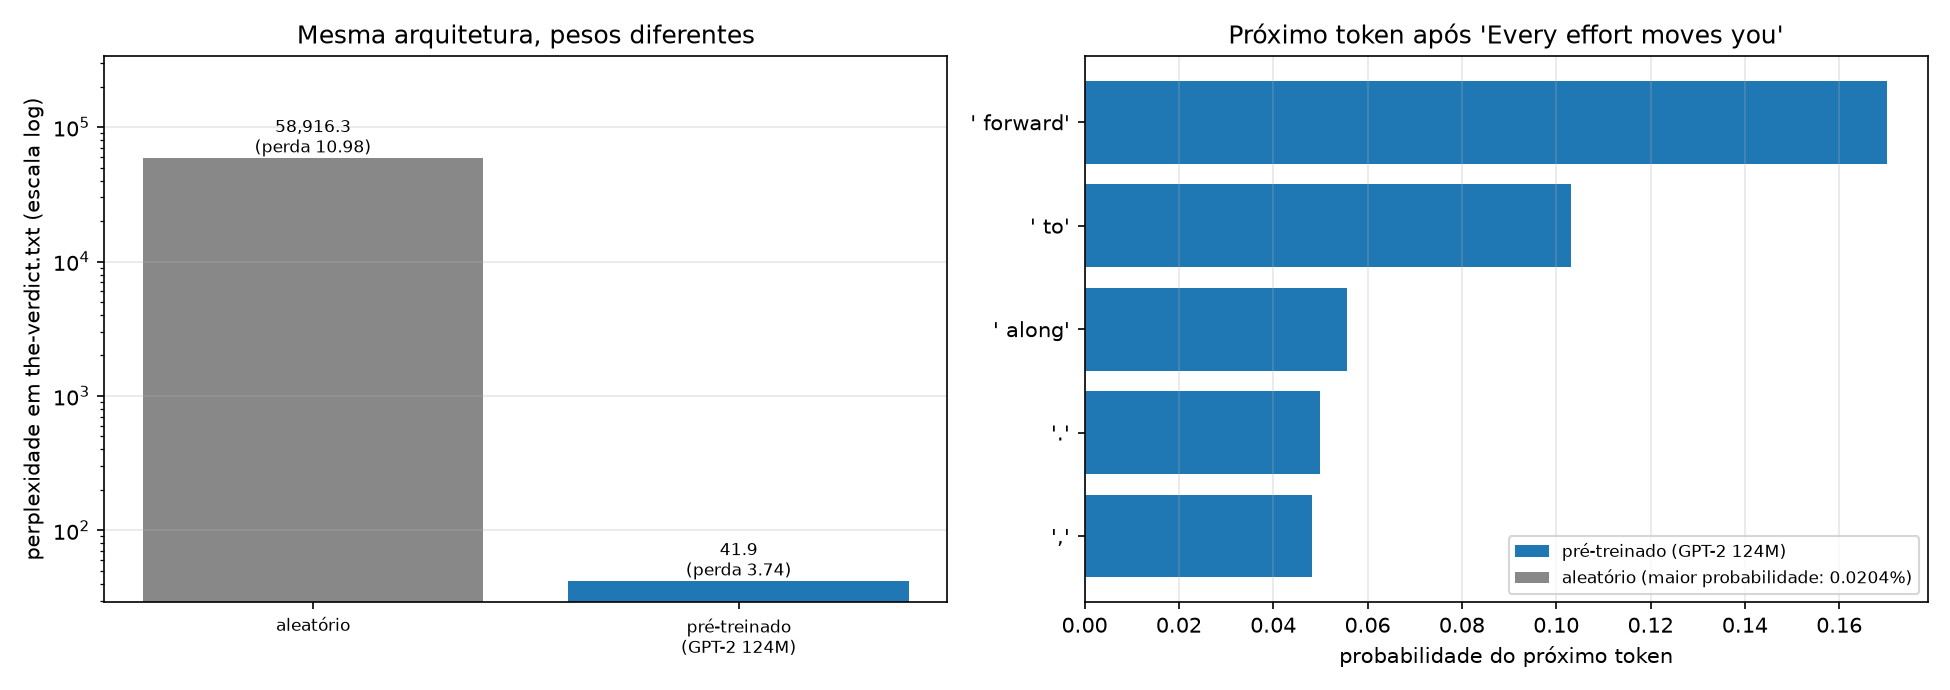

>> aleatório
Cinco próximos tokens mais prováveis: 'arcity' (0.02%), 'INT' (0.02%), '..................' (0.02%), ' equ' (0
  [greedy] Every effort moves youarcity warrQu motivateYS Coreints kernel 220redited Tooth m BLACK econom soloador CostPaTesformation Chow metabolism congratTime 

>> pré-treinado (GPT-2 124M)
Cinco próximos tokens mais prováveis: ' forward' (17.02%), ' to' (10.30%), ' along' (5.57%), '.' (4.99%), ',' 
  [greedy] Every effort moves you forward. 



In [4]:
display(tabela("exp01-aleatorio-vs-pretreinado"))
figura("exp01-aleatorio-vs-pretreinado")
amostras = (RESULTADOS / "exp01-amostras.txt").read_text(encoding="utf-8")
for bloco in amostras.split("=" * 70)[1:]:
    linhas = [l for l in bloco.strip().splitlines() if l.strip()]
    if len(linhas) > 3:
        print(linhas[0][:110]); print("  [greedy]", linhas[2][:150], "\n")
    else:
        print(">>", linhas[0])

O modelo aleatório tem perda ≈ `ln(50257) = 10,82`: para ele todos os tokens são igualmente prováveis, e a
perplexidade fica na casa do tamanho do vocabulário. Com os pesos do GPT-2 a perplexidade cai para ≈ 42 e o
texto gerado é inglês gramatical. Nenhuma linha de `gpt.py` mudou — **o conhecimento está nos pesos**.

## 3. Fine-tuning de classificação: dados, cabeça e congelamento (seções 6.2 a 6.5)

A tarefa: dizer se um SMS é *spam*. A base (*SMS Spam Collection*, UCI) tem 5.574 mensagens, 87% legítimas.
Três cuidados na preparação:

- **remover duplicatas** — 403 mensagens são repetidas; se ficassem, a mesma mensagem poderia cair no treino e
  no teste (o livro não faz essa remoção);
- **balancear** — sorteamos tantas mensagens legítimas quantas há de spam, para que "tudo é legítimo" não
  seja uma resposta com 87% de acerto;
- **dividir** em treino (70%), validação (10%) e teste (20%).

In [5]:
bruto = carregar_base_spam()
unico = remover_duplicatas(bruto)
balanceado = balancear_classes(unico)
print(f"lidas {len(bruto)} -> únicas {len(unico)} -> balanceadas {len(balanceado)} "
      f"({(balanceado.rotulo == 1).sum()} spam + {(balanceado.rotulo == 0).sum()} não spam)")
partes = {n: pd.read_csv(PASTA_SPAM / f"{n}.csv") for n in ("treino", "validacao", "teste")}
print({n: len(p) for n, p in partes.items()})

ds = DatasetDeClassificacao(partes["treino"].head(200), tok, max_length=64)
ids, rotulo = ds[3]
print("\nmensagem :", partes["treino"].texto[3][:70])
print("rótulo   :", int(rotulo), f"({NOMES_DAS_CLASSES[int(rotulo)]})")
print("token IDs:", ids[:12].tolist(), "...", ids[-4:].tolist(), f"({len(ids)} posições; 50256 = padding)")

lidas 5574 -> únicas 5171 -> balanceadas 1306 (653 spam + 653 não spam)
{'treino': 914, 'validacao': 130, 'teste': 262}

mensagem : Am not interested to do like that.
rótulo   : 0 (não spam)
token IDs: [5840, 407, 4609, 284, 466, 588, 326, 13, 50256, 50256, 50256, 50256] ... [50256, 50256, 50256, 50256] (64 posições; 50256 = padding)


Um lote precisa ser um tensor retangular; as mensagens curtas são completadas à direita com `<|endoftext|>`
(50256) — o **padding**.

### A cabeça de classificação e as camadas congeladas

O GPT devolve, para cada posição, 50.257 notas (uma por token do vocabulário). Para classificar bastam 2.
Trocamos a última camada, `Linear(768, 50257)`, por uma `Linear(768, 2)` nova, de pesos aleatórios — a
**cabeça de classificação** — e **congelamos** quase todo o resto (`requires_grad = False`): só a cabeça, o
último bloco Transformer e a norma final continuam treináveis.

In [6]:
m = modelo_pequeno()
print("antes :", m.out_head, "| treináveis: {:,} de {:,}".format(*contar_treinaveis(m)))
adaptar_para_classificacao(m, num_classes=2, blocos_treinaveis=1)
print("depois:", m.out_head, "| treináveis: {:,} de {:,}".format(*contar_treinaveis(m)))
print()
for nome, modulo in [("embeddings", m.embedding), ("bloco 0", m.trf_blocks[0]), ("bloco 1 (último)", m.trf_blocks[1]),
                     ("norma final", m.final_norm), ("cabeça", m.out_head)]:
    estado = {p.requires_grad for p in modulo.parameters()}
    print(f"  {nome:<18}", "treinável" if estado == {True} else "congelado")

x = ds[3][0].unsqueeze(0)
print("\nsaída do modelo :", tuple(m(x).shape), "-> usamos só a última posição:", tuple(logits_de_classe(m, x).shape))

antes : Linear(in_features=64, out_features=50257, bias=False) | treináveis: 6,537,088 de 6,537,088
depois: Linear(in_features=64, out_features=2, bias=True) | treináveis: 50,242 de 3,320,770

  embeddings         congelado
  bloco 0            congelado
  bloco 1 (último)   treinável
  norma final        treinável
  cabeça             treinável



saída do modelo : (1, 64, 2) -> usamos só a última posição: (1, 2)


**Por que a última posição?** Por causa da máscara causal da Sprint 3: cada token só enxerga os anteriores, de
modo que o último é o único cujo vetor foi calculado a partir da mensagem inteira. No GPT-2 124M, a
configuração acima deixa 7.090.946 parâmetros treináveis de 124.441.346 (5,7%).

## 4. Treino e avaliação do classificador (seções 6.6 a 6.8)

O laço é o da Sprint 5 com duas trocas: a perda é a entropia cruzada entre os 2 logits do último token e o
rótulo, e além da perda acompanhamos a **acurácia**. Abaixo, o laço completo num modelo pequeno, treinado do
zero em 200 mensagens — só para ver o mecanismo funcionar em segundos.

In [7]:
lt = DataLoader(ds, batch_size=8, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(123))
lv = DataLoader(DatasetDeClassificacao(partes["validacao"], tok, max_length=64), batch_size=8)
m = adaptar_para_classificacao(modelo_pequeno(), blocos_treinaveis=None)   # pequeno e sem pré-treino: treina tudo
antes = acuracia_do_loader(lv, m, "cpu")
h = treinar_classificador(m, lt, lv, torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.1), "cpu",
                          num_epocas=5, verboso=False)
print(f"acurácia na validação: {antes:.1%} -> {h['acuracia_validacao'][-1]:.1%}")
r = metricas_de_classificacao(lv, m, "cpu")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})
for texto in ["You are a winner! Call now to claim your free prize of 1000 cash.",
              "Hey, are we still meeting for dinner tonight?"]:
    classe, probs = classificar_texto(texto, m, tok, max_length=64)
    print(f"{classe:>9} ({probs[classe]:.0%}) <- {texto}")

acurácia na validação: 51.5% -> 90.0%
{'vp': 62, 'fp': 11, 'vn': 53, 'fn': 4, 'acuracia': 0.885, 'precisao': 0.849, 'revocacao': 0.939, 'f1': 0.892}
     spam (99%) <- You are a winner! Call now to claim your free prize of 1000 cash.
 não spam (96%) <- Hey, are we still meeting for dinner tonight?


### O treino de verdade: GPT-2 124M

`treinar_classificador.py`: 5 épocas, AdamW (`lr = 5e-5`, `weight_decay = 0,1`), lotes de 8, 914 mensagens de
treino. Em CPU, 40 minutos.

{'parametros_treinaveis': 7090946, 'parametros_totais': 124441346, 'dispositivo': 'cpu', 'tempo_de_treino_s': 2401.4, 'acuracia_treino': 0.9660087719298246, 'acuracia_validacao': 0.9692307692307692, 'acuracia_teste': 0.9809160305343512, 'perda_validacao': 0.10401198840768569, 'perda_teste': 0.06565609001060665}


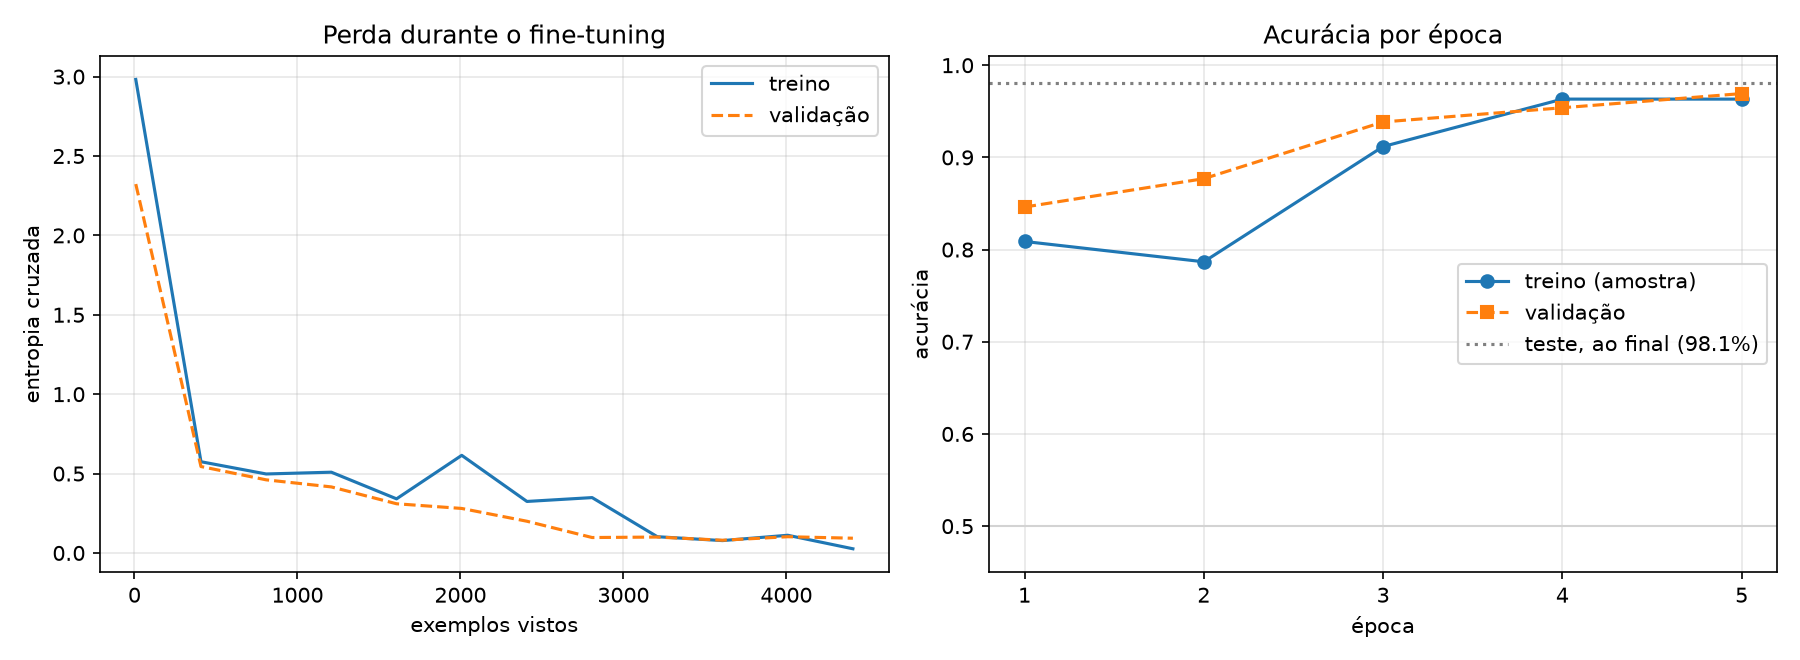

In [8]:
cfg_treino = json.loads((RESULTADOS / "classificador-config.json").read_text(encoding="utf-8"))
print({k: v for k, v in cfg_treino.items() if not isinstance(v, (dict, list))})
figura("classificador-curvas")

### Antes × depois, no conjunto de teste

A acurácia sozinha esconde **que tipo** de erro o modelo comete. A matriz de confusão separa os quatro casos,
tomando *spam* como a classe positiva, e dela saem:

- **precisão** = VP / (VP + FP): das mensagens marcadas como spam, quantas eram;
- **revocação** = VP / (VP + FN): dos spams que existiam, quantos foram pegos;
- **F1** = média harmônica das duas.

,modelo,exemplos,acuracia,precisao,revocacao,f1,vp,fp,vn,fn
0,antes do fine-tuning,262,0.4542,0.4542,1.0000,0.6247,119,143,0,0
1,depois do fine-tuning,262,0.9809,0.9914,0.9664,0.9787,115,1,142,4


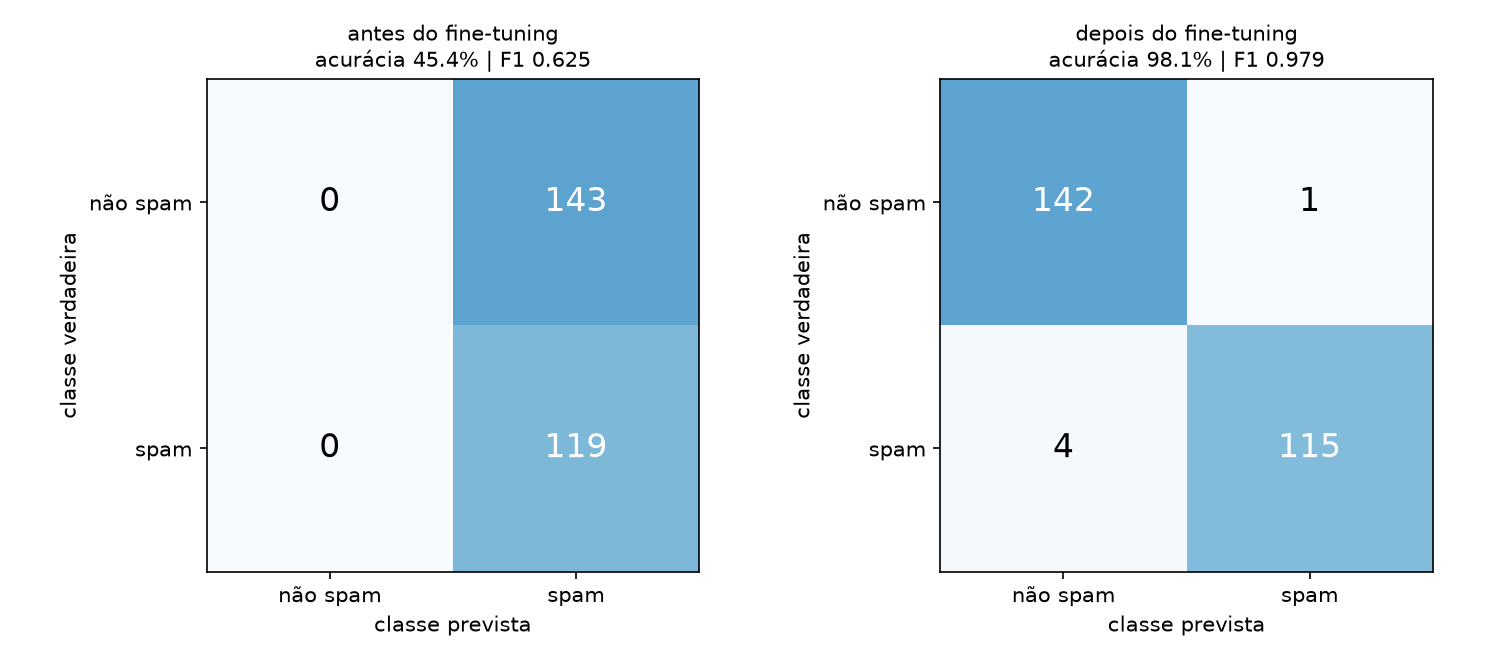

conferindo à mão a linha 'depois': {'acuracia': 0.9809, 'precisao': 0.9914, 'revocacao': 0.9664, 'f1': 0.9787}


In [9]:
display(tabela("exp02-antes-e-depois"))
figura("exp02-antes-e-depois")
print("conferindo à mão a linha 'depois':", {k: round(v, 4) for k, v in metricas_da_matriz(115, 1, 142, 4).items()})

Antes do ajuste a cabeça é aleatória e o modelo responde "spam" para tudo: acerta os 45% que são spam
(revocação 100%) e erra todo o resto. Depois, 98,1% de acerto em mensagens que nunca viu, com um único falso
positivo — o erro mais caro num filtro, porque esconde uma mensagem legítima.

### Quanto do modelo precisa ser treinado? E de qual token ler a classe?

,configuracao,treinaveis,fracao_treinavel,acuracia_validacao,acuracia_teste,tempo_min,origem
0,só a cabeça,1538,0.0000,0.8692,0.8359,32.0467,este experimento
1,último bloco,7090946,0.0570,0.9692,0.9809,40.0233,treinar_classificador.py
2,metade do modelo,42530306,0.3418,0.9769,0.9924,53.6838,este experimento


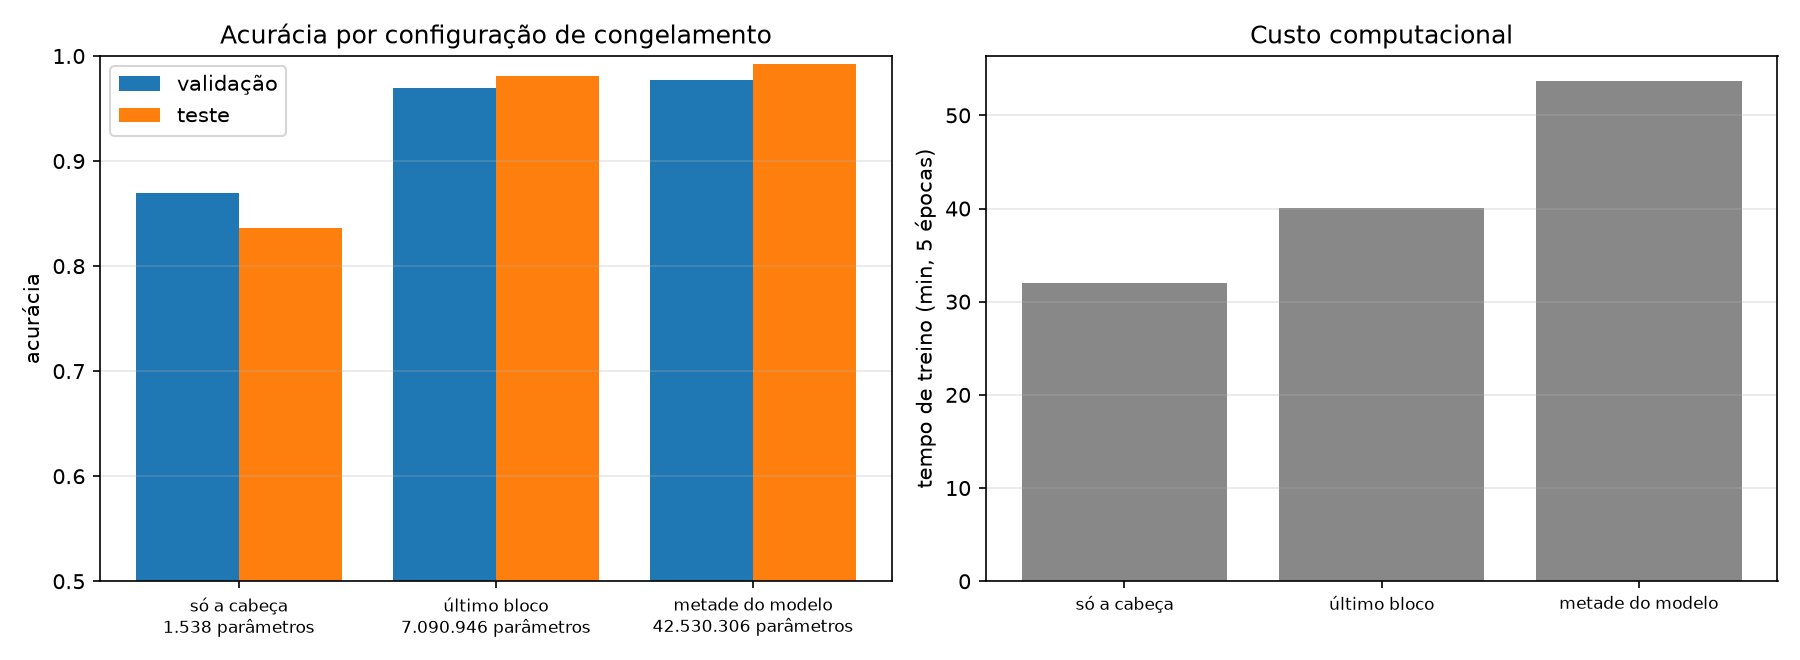

,posicao,tokens_visiveis,acuracia_validacao,acuracia_teste,tempo_min,origem
0,último token,mensagem inteira,0.9692,0.9809,40.0233,treinar_classificador.py
1,primeiro token,só o primeiro,0.6846,0.6450,34.0290,este experimento
2,regra de contagem pelo primeiro token (sem modelo),só o primeiro,-,0.7443,0.0000,contagem no treino


In [10]:
display(tabela("exp03-camadas-treinaveis"))
figura("exp03-camadas-treinaveis")
display(tabela("exp04-token-de-classificacao"))

- **Só a cabeça** (1.538 parâmetros) chega a 83,6%: as representações do GPT-2 já separam boa parte das
  mensagens, mas não foram feitas para isso. Liberar **um bloco** leva a 98,1%; liberar **seis** rende mais
  1 ponto e custa 34% a mais de tempo. O tempo cai pouco quando se congela mais porque o passo direto pelos
  12 blocos continua sendo feito.
- Lendo a classe no **primeiro token**, a acurácia despenca para 64,5%: ele só enxerga a si mesmo. Uma
  tabela de contagem das primeiras palavras do treino acerta 74,4%. É a máscara causal, vista pelo
  resultado.

## 5. Fine-tuning de instruções: prompt e lotes (seções 7.2 a 7.4)

Agora a arquitetura **não muda**: mesma cabeça de 50.257 saídas, mesma perda de próximo token, mesmo laço
`treinar_modelo` da Sprint 5. O que muda são os dados. Cada exemplo tem instrução, entrada opcional e
resposta, e vira um texto único no formato **Alpaca**.

In [11]:
treino, validacao, teste = preparar_instrucoes()
print(f"treino {len(treino)} | validação {len(validacao)} | teste {len(teste)}  "
      "(1.100 exemplos, menos 25 instruções repetidas)\n")
com_entrada = next(e for e in treino if e["input"])
print(formatar_exemplo(com_entrada))
print("\n--- o prompt de inferência é o mesmo texto, cortado depois de '### Response:' ---")
print(repr(montar_prompt(com_entrada)[-60:]))

treino 913 | validação 55 | teste 107  (1.100 exemplos, menos 25 instruções repetidas)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Evaluate the following phrase by transforming it into the spelling given.

### Input:
freind --> friend

### Response:
The spelling of the given phrase "freind" is incorrect, the correct spelling is "friend".

--- o prompt de inferência é o mesmo texto, cortado depois de '### Response:' ---
'pelling given.\n\n### Input:\nfreind --> friend\n\n### Response:\n'


### A montagem do lote (*collate*)

Os prompts têm tamanhos diferentes. `agrupar_lote` completa cada um até o maior **do lote**, cria o alvo
deslocado em uma posição e troca o padding do alvo por `-100`, o valor que a entropia cruzada do PyTorch
ignora. Fica um único `<|endoftext|>` no alvo: é ele que ensina o modelo a **parar**.

In [12]:
entrada, alvo = agrupar_lote([[0, 1, 2, 3, 4], [5, 6], [7, 8, 9]])
print("entrada:\n", entrada, "\nalvo:\n", alvo)

lt, lv, _ = criar_loaders_instrucoes(treino, validacao, teste, tok)
formas = [tuple(e.shape) for e, _ in lt]
print(f"\n{len(lt)} lotes de treino; comprimentos de {min(f[1] for f in formas)} a {max(f[1] for f in formas)} tokens")
e, a = next(iter(lv))
print(f"um lote de validação: {tuple(e.shape)}, {int((a == -100).sum())} de {a.numel()} posições ignoradas na perda")

entrada:
 tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]]) 
alvo:
 tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])



114 lotes de treino; comprimentos de 54 a 91 tokens
um lote de validação: (8, 76), 140 de 608 posições ignoradas na perda


## 6. Treino, geração e avaliação das respostas (seções 7.5 a 7.8)

Num modelo pequeno, sem pré-treino, o melhor que dá para mostrar em segundos é o mecanismo: decorar 4
exemplos e conferir que `responder` devolve **só a resposta** e **para sozinho** no `<|endoftext|>`.

In [13]:
exemplos = treino[:4]
m = modelo_pequeno(emb_dim=128, context_length=128)
lt4, lv4, _ = criar_loaders_instrucoes(exemplos, exemplos, exemplos, tok, batch_size=4, max_length=128)
with contextlib.redirect_stdout(io.StringIO()):
    h = treinar_modelo(m, lt4, lv4, torch.optim.AdamW(m.parameters(), lr=2e-3), "cpu", num_epocas=150,
                       frequencia_avaliacao=50, lotes_avaliacao=1)
print(f"perda: {h['perda_treino'][0]:.2f} -> {h['perda_treino'][-1]:.3f}\n")
for ex in exemplos[:3]:
    print("instrução:", ex["instruction"], ex["input"])
    print("  esperada:", ex["output"])
    print("  gerada  :", responder(ex, m, tok, max_novos_tokens=60), "\n")
novo = modelo_pequeno(n_layers=1, context_length=128)
print("modelo sem treino, limite de 12 tokens:", repr(responder(exemplos[0], novo, tok, max_novos_tokens=12)))

perda: 10.28 -> 0.030

instrução: Evaluate the following phrase by transforming it into the spelling given. freind --> friend
  esperada: The spelling of the given phrase "freind" is incorrect, the correct spelling is "friend".


  gerada  : The spelling of the given phrase "freind" is incorrect, the correct spelling is "friend". 

instrução: Edit the following sentence for grammar. He go to the park every day.
  esperada: He goes to the park every day.


  gerada  : He goes to the park every day. 

instrução: Convert 45 kilometers to meters. 
  esperada: 45 kilometers is 45000 meters.
  gerada  : 45 kilometers is 45000 meters. 



modelo sem treino, limite de 12 tokens: 'Sprite indoor MouseABC repealleaders "< handledexample William magazines undone'


### O treino de verdade: GPT-2 124M

`treinar_instrucoes.py`: 2 épocas sobre os 913 exemplos, AdamW (`lr = 5e-5`, `weight_decay = 0,1`), lotes de 8.
Por limitação da máquina (CPU, 7,5 GB de RAM), o modelo é o 124M com os **6 últimos blocos** treináveis; o
livro ajusta o 355M inteiro.

{'parametros_treinaveis': 42528768, 'parametros_totais': 163037184, 'dispositivo': 'cpu', 'tempo_de_treino_s': 865.0, 'perda_treino_inicial': 4.014, 'perda_validacao_inicial': 4.096, 'perda_treino_final': 0.599, 'perda_validacao_final': 0.78}


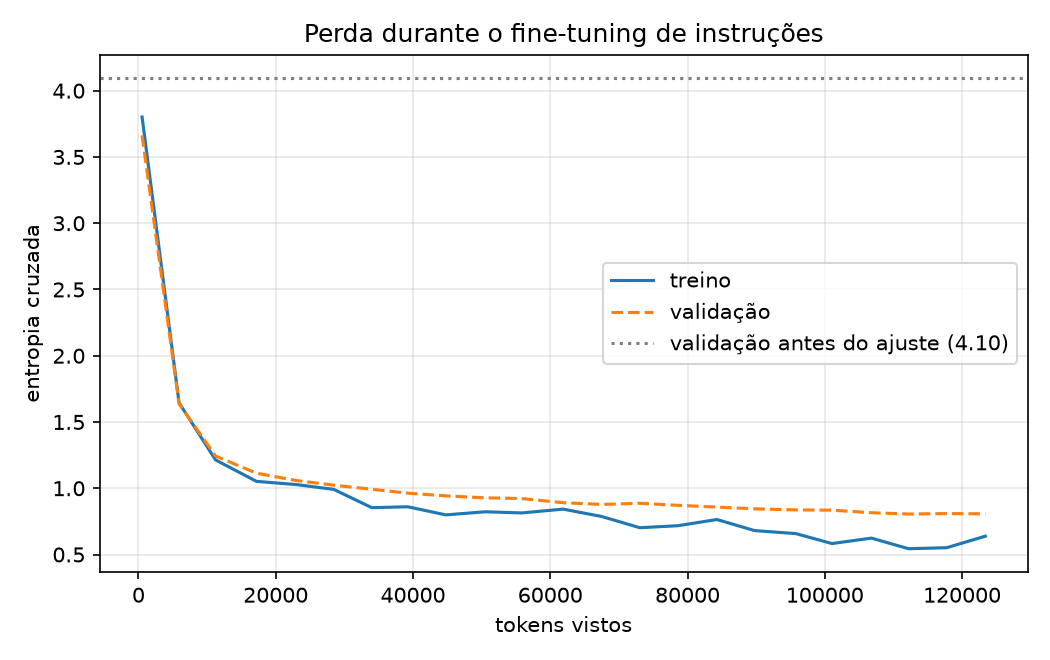

Resposta gerada ao fim de cada época (greedy, 40 tokens) para a instrução:

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is the past tense of 'think'?

### Response:


Resposta esperada: The past tense of 'think' is 'thought'.

Época 1: "The past tense of 'think' is 'think'.<|endoftext|>The following is an instruction that describes a task. Write a response that appropriately completes the request.\n\n### Instruction:\nWhat is the"
Época 2: "The past tense of 'think' is 'to think'.<|endoftext|>The U.S. Department of Agriculture (USDA) recently issued a new rule that requires all farm products to be labeled as such"



In [14]:
resumo = json.loads((RESULTADOS / "instrucoes-config.json").read_text(encoding="utf-8"))
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in resumo.items() if not isinstance(v, dict)})
figura("instrucoes-curvas")
print((RESULTADOS / "instrucoes-amostras.txt").read_text(encoding="utf-8"))

### Avaliação das respostas no conjunto de teste

Não há uma resposta única certa, então não há uma métrica só. Usamos duas automáticas e a leitura:

- **correspondência exata** — mesmas palavras, na mesma ordem (ignorando caixa e pontuação);
- **F1 de palavras** — sobreposição entre as palavras geradas e as esperadas.

O livro usa um segundo LLM como juiz; não usamos, por depender de um modelo pronto de terceiros.

as métricas, em exemplos pequenos:
  exata=True  F1=1.00  'The capital of France is Paris.' x 'the capital of france is paris'
  exata=False F1=0.67  'The cat sat.' x 'The cat sat on the mat.'
  exata=False F1=0.29  'Paris.' x 'The capital of France is Paris.'


,modelo,exemplos_de_teste,exemplos,correspondencia_exata,f1_de_palavras,palavras_geradas,palavras_esperadas
0,pré-treinado,todos,107,0.0000,0.2029,23.8598,8.4019
1,pré-treinado,com entrada,30,0.0000,0.2124,20.2000,5.8000
2,pré-treinado,sem entrada,77,0.0000,0.1992,25.2857,9.4156
3,ajustado,todos,107,0.0748,0.5277,8.5327,8.4019
4,ajustado,com entrada,30,0.0000,0.4879,6.4333,5.8000
5,ajustado,sem entrada,77,0.1039,0.5431,9.3506,9.4156


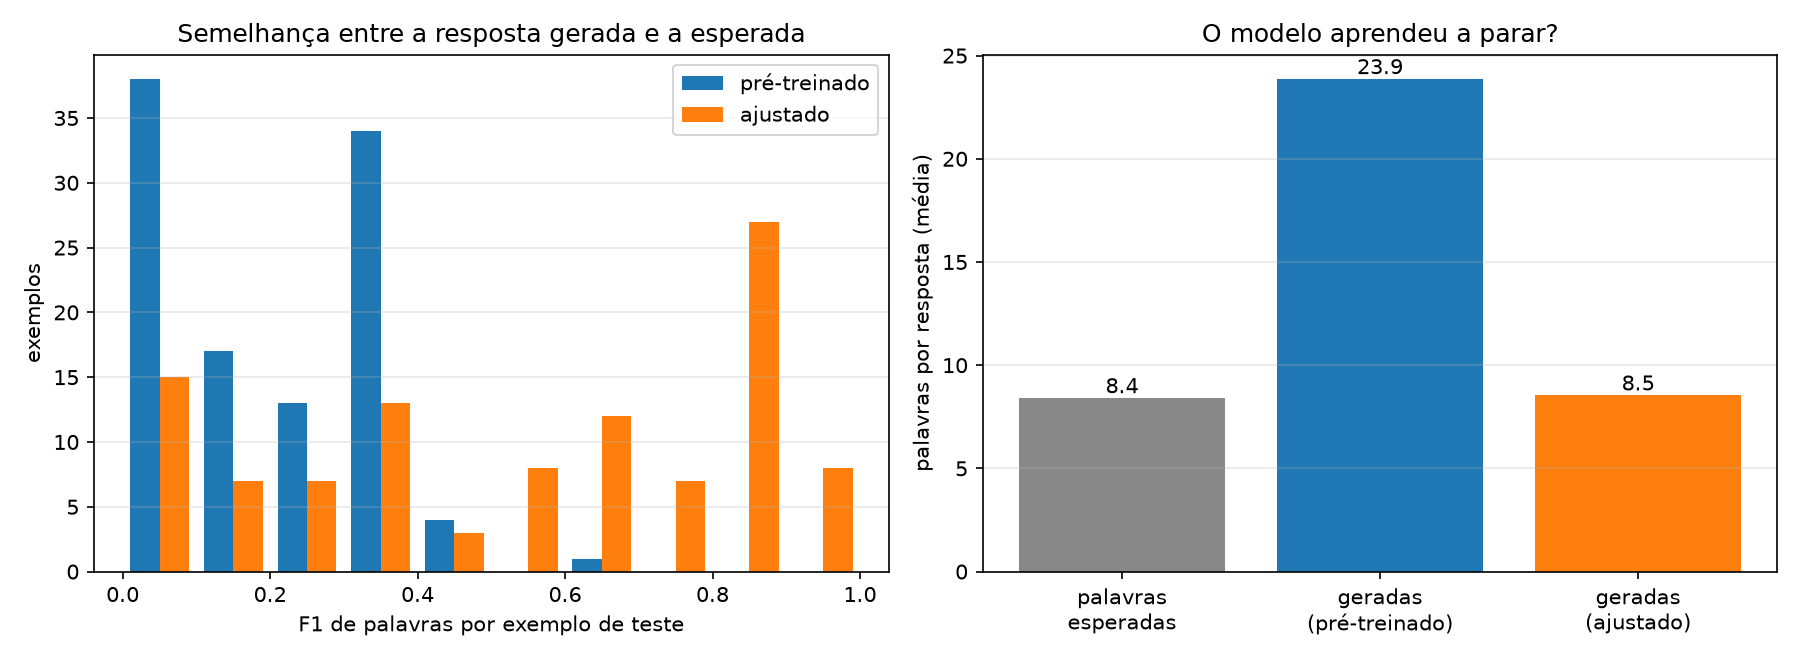

In [15]:
print("as métricas, em exemplos pequenos:")
for gerada, esperada in [("The capital of France is Paris.", "the capital of france is paris"),
                         ("The cat sat.", "The cat sat on the mat."), ("Paris.", "The capital of France is Paris.")]:
    print(f"  exata={correspondencia_exata(gerada, esperada)!s:<5} F1={f1_de_palavras(gerada, esperada):.2f}  "
          f"{gerada!r} x {esperada!r}")

display(tabela("exp06-avaliacao-das-respostas"))
figura("exp06-avaliacao-das-respostas")

In [16]:
respostas = json.loads((RESULTADOS / "exp05-respostas-de-teste.json").read_text(encoding="utf-8"))
for r in respostas[:6]:
    print("instrução:", r["instruction"], r["input"])
    print("  esperada:", r["output"])
    print("  ajustado:", r["resposta_depois"])
    print("  antes   :", repr(r["resposta_antes"][:110]), "\n")

instrução: Combine the two sentences into a single coherent sentence. She studied hard. She passed the exam.
  esperada: She studied hard, so she passed the exam.
  ajustado: She passed the exam.
  antes   : 'She passed the exam.\n\n### Output:\n\nShe passed the exam.\n\n### Error:\n\nShe passed the exam.\n\n### Error:\n\nShe pas' 

instrução: Explain the process of combustion. 
  esperada: Combustion is a chemical process in which a substance reacts rapidly with oxygen, releasing heat and light. It typically produces carbon dioxide, water, and energy.
  ajustado: The process of combustion is a process of combustion that occurs when a substance is heated by a process of heat transfer.
  antes   : 'Write a response that is appropriate for the task.\n\n### Response:\n\nWrite a response that is appropriate for th' 

instrução: Convert the given sentence into active voice. The proposal was approved by the committee.
  esperada: The committee approved the proposal.
  ajustado: The proposal 

**Leitura dos resultados.**

- **O ajuste mudou o comportamento.** O modelo pré-treinado repete a instrução ou o molde até esgotar os 48
  tokens (23,9 palavras por resposta). O ajustado responde uma vez e para: 8,5 palavras, contra 8,4 das
  respostas esperadas. Ele aprendeu o formato e o `<|endoftext|>`.
- **Mas não deu o conteúdo.** Só 8 das 107 respostas (7,5%) coincidem com a esperada. Em 16 das 30 instruções
  com entrada, a resposta é a própria entrada copiada, sem a transformação pedida.
- **O F1 engana.** Ele sobe de 0,20 para 0,53, mas "The chemical formula for ammonium nitrate is NaCl." tem F1
  0,88 contra a resposta certa (NH4NO3): 7 das 8 palavras coincidem. F1 de palavras mede semelhança de
  redação, não correção — por isso a leitura de amostras, e por isso o livro usa um LLM como juiz.
- **A causa é a escala:** GPT-2 124M (o livro usa o 355M), 6 blocos treináveis e 913 exemplos. Esses exemplos
  ensinam um formato; os fatos teriam de estar no modelo pré-treinado.

## 7. Síntese

| | Pré-treino (Sprint 5) | Fine-tuning de classificação | Fine-tuning de instruções |
|---|---|---|---|
| Ponto de partida | pesos aleatórios | pesos do GPT-2 | pesos do GPT-2 |
| Dados | texto sem rótulo | 914 mensagens rotuladas | 913 pares instrução → resposta |
| Arquitetura | `GPTModel` | cabeça trocada por `Linear(768, 2)` | a mesma |
| Perda | próximo token, todas as posições | classe, no último token | próximo token, sem o padding |
| Saída | texto | uma classe | texto que termina sozinho |
| Avaliação | perda e perplexidade | acurácia, precisão, revocação, F1 | correspondência exata, F1 de palavras, leitura |

O mesmo `GPTModel`, escrito nas Sprints 2 a 4, serve aos três usos. O que distingue um modelo que escreve
ruído de um que classifica spam ou responde a pedidos são **os pesos** — e o fine-tuning mostra que, partindo
de pesos pré-treinados, bastam cerca de 900 exemplos e alguns minutos de treino para mudar o comportamento.

Detalhes, limitações e todos os números: [`reports/sprint06-relatorio.md`](../reports/sprint06-relatorio.md).